<a href="https://colab.research.google.com/github/shin-noda/algorithm-visualizer-3d/blob/main/Titanic_ver1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [46]:
import pandas as pd

file_path = '/content/drive/MyDrive/Colab Notebooks/Kaggle/Titanic - Machine Learning from Disaster/data'
train_path, test_path = file_path + '/train.csv', file_path + '/test.csv'

In [89]:
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# Fill NaN columns in Age
age_median = df_train['Age'].median()

df_train['Age'] = df_train['Age'].fillna(age_median)
df_test['Age'] = df_test['Age'].fillna(age_median)

# Age & Fare: Normalize with Min-Max scaling
# Note: use the same age_min, max, fare_min, max for both training and testing.
age_min = df_train['Age'].min()
age_max = df_train['Age'].max()

fare_min = df_train['Fare'].min()
fare_max = df_train['Fare'].max()

df_train['Age'] = (df_train['Age'] - age_min) / (age_max - age_min)
df_train['Fare'] = (df_train['Fare'] - fare_min) / (fare_max - fare_min)
df_test['Age'] = (df_test['Age'] - age_min) / (age_max - age_min)
df_test['Fare'] = (df_test['Fare'] - fare_min) / (fare_max - fare_min)

# Name: Keep Mr., Mrs, etc.
df_train['Title'] = df_train['Name'].str.split(', ').str[1].str.split('.').str[0]
df_test['Title'] = df_test['Name'].str.split(', ').str[1].str.split('.').str[0]

# Create a new column 'HasCabin'
df_train['HasCabin'] = df_train['Cabin'].notna().astype(int)
df_test['HasCabin'] = df_test['Cabin'].notna().astype(int)

# Extract the first letter of 'Cabin'.
df_train['Deck'] = df_train['Cabin'].str[0].fillna('NaN')
df_test['Deck'] = df_test['Cabin'].str[0].fillna('NaN')

# One-Hot encoding
categorical_cols = ['Sex', 'Embarked', 'Title', 'Deck']
df_train = pd.get_dummies(df_train, columns=categorical_cols)
df_test = pd.get_dummies(df_test, columns=categorical_cols)

# Drop some columns.
drop_cols = ['PassengerId', 'Name', 'Ticket', 'Deck_NaN', 'Cabin']
df_train = df_train.drop(columns=drop_cols)
df_test = df_test.drop(columns=drop_cols)

# Combine all columns
all_columns = df_train.columns.union(df_test.columns)

# Make both DataFrames use exactly those columns
df_train = df_train.reindex(columns=all_columns, fill_value=False)
df_test = df_test.reindex(columns=all_columns, fill_value=False)

# Drop the 'Survived' column in df_test
df_test = df_test.drop(columns=['Survived'])

In [90]:
df_train.head()

,Age,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Embarked_C,...,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,0.271174,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
1,0.472229,False,False,True,False,False,False,False,False,True,...,False,False,False,False,False,True,False,False,False,False
2,0.321438,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
3,0.434531,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
4,0.434531,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False


In [91]:
df_test.head()

,Age,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Embarked_C,...,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,0.428248,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
1,0.585323,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2,0.773813,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3,0.334004,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,0.271174,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False


In [92]:
import keras
from keras import layers

def get_model():
    model = keras.Sequential(
        [
            layers.Dense(64, activation="relu"),
            layers.Dense(64, activation="relu"),
            layers.Dense(1, activation="sigmoid"),
        ]
    )

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [93]:
x_train, y_train = df_train.drop(columns=['Survived']), df_train['Survived']

# Note: there is no y_test available. (No 'Survived' column in the test data.)
x_test = df_test

In [94]:
# Convert them to float32
x_train = x_train.to_numpy(dtype="float32")
y_train = y_train.to_numpy(dtype="float32")

In [112]:
import numpy as np

def k_fold_validation(num_epochs):
    # Using K-Fold validation
    k = 4
    num_val_samples = len(df_train) // k
    all_acc_history = []

    for i in range(k):
        print(f"Processing fold #{i + 1}")

        # Prepares the validation data: data from partition #k
        fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
        fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]

        # Prepares the training data: data from all other partitions
        fold_x_train = np.concatenate(
            [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
            axis=0
        )

        fold_y_train = np.concatenate(
            [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
            axis=0
        )

        # Builds the model
        model = get_model()

        # Train the model
        history = model.fit(
            fold_x_train,
            fold_y_train,
            validation_data=(fold_x_val, fold_y_val),
            epochs=num_epochs,
            batch_size=16,
            verbose=0,
        )

        acc_history = history.history["val_accuracy"]
        all_acc_history.append(acc_history)

    return all_acc_history

In [113]:
num_epochs = 50
all_acc_history = k_fold_validation(num_epochs)

# Compute the average of per-epoch accuracy
average_acc_history = [
    np.mean([x[i] for x in all_acc_history]) for i in range(num_epochs)
]

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


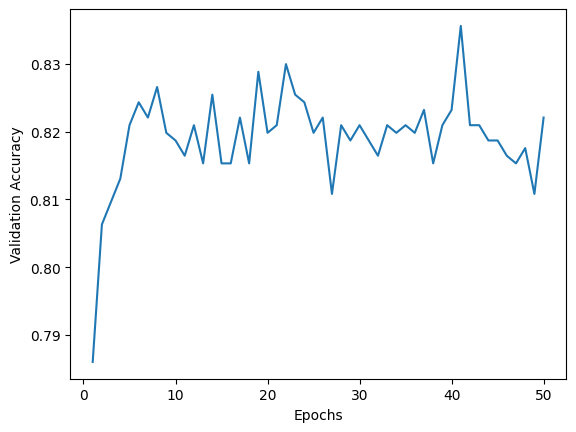

In [114]:
import matplotlib.pyplot as plt

epochs = range(1, len(average_acc_history) + 1)

plt.plot(epochs, average_acc_history)
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.show()

In [115]:
num_epochs = 100
all_acc_history = k_fold_validation(num_epochs)

# Compute the average of per-epoch accuracy
average_acc_history = [
    np.mean([x[i] for x in all_acc_history]) for i in range(num_epochs)
]

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


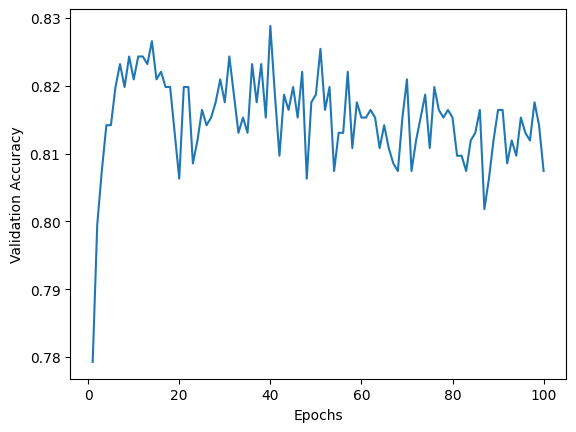

In [116]:
# Clears the figure
plt.clf()

epochs = range(1, len(average_acc_history) + 1)

plt.plot(epochs, average_acc_history)
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.show()

In [117]:
num_epochs = 150
all_acc_history = k_fold_validation(num_epochs)

# Compute the average of per-epoch accuracy
average_acc_history = [
    np.mean([x[i] for x in all_acc_history]) for i in range(num_epochs)
]

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


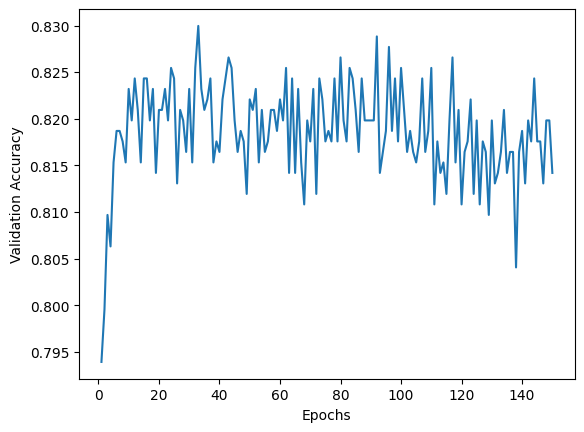

In [118]:
# Clears the figure
plt.clf()

epochs = range(1, len(average_acc_history) + 1)

plt.plot(epochs, average_acc_history)
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.show()

In [119]:
num_epochs = 200
all_acc_history = k_fold_validation(num_epochs)

# Compute the average of per-epoch accuracy
average_acc_history = [
    np.mean([x[i] for x in all_acc_history]) for i in range(num_epochs)
]

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


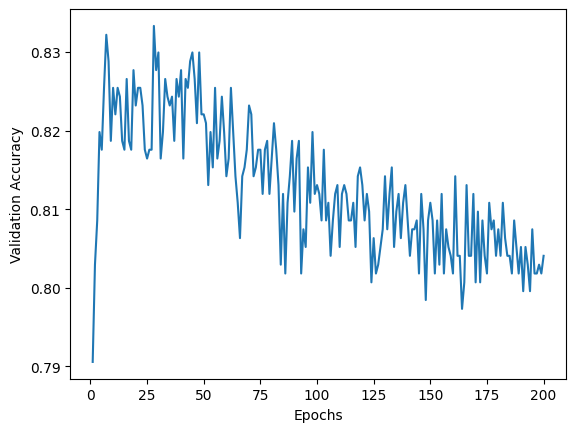

In [120]:
# Clears the figure
plt.clf()

epochs = range(1, len(average_acc_history) + 1)

plt.plot(epochs, average_acc_history)
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.show()

In [121]:
num_epochs = 15
all_acc_history = k_fold_validation(num_epochs)

# Compute the average of per-epoch accuracy
average_acc_history = [
    np.mean([x[i] for x in all_acc_history]) for i in range(num_epochs)
]

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


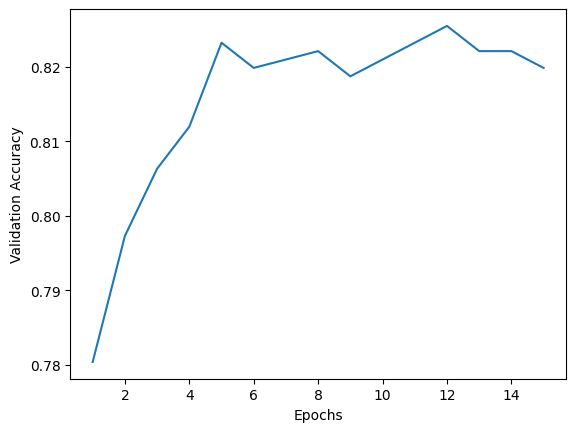

In [122]:
# Clears the figure
plt.clf()

epochs = range(1, len(average_acc_history) + 1)

plt.plot(epochs, average_acc_history)
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.show()

In [123]:
num_epochs = 20
all_acc_history = k_fold_validation(num_epochs)

# Compute the average of per-epoch accuracy
average_acc_history = [
    np.mean([x[i] for x in all_acc_history]) for i in range(num_epochs)
]

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


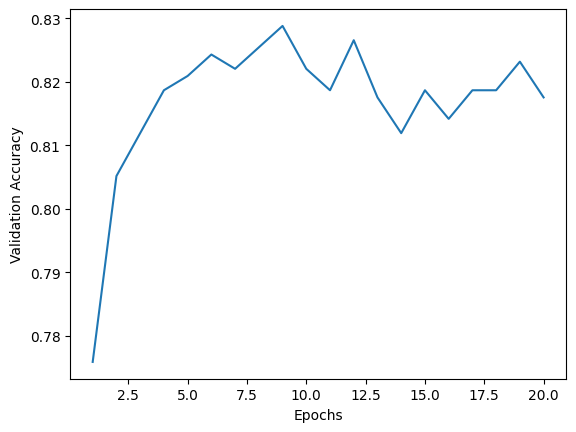

In [124]:
# Clears the figure
plt.clf()

epochs = range(1, len(average_acc_history) + 1)

plt.plot(epochs, average_acc_history)
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.show()

In [125]:
num_epochs = 10
all_acc_history = k_fold_validation(num_epochs)

# Compute the average of per-epoch accuracy
average_acc_history = [
    np.mean([x[i] for x in all_acc_history]) for i in range(num_epochs)
]

Processing fold #1
Processing fold #2
Processing fold #3
Processing fold #4


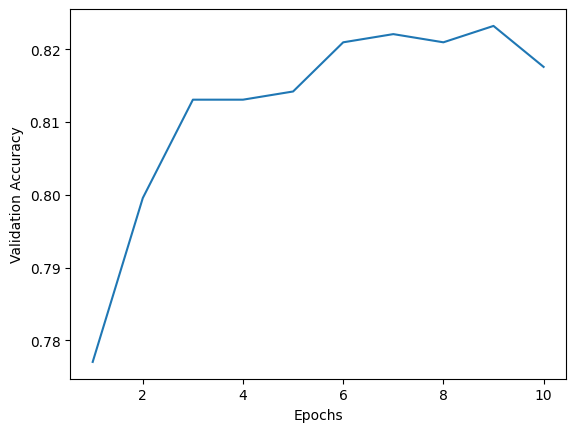

In [126]:
# Clears the figure
plt.clf()

epochs = range(1, len(average_acc_history) + 1)

plt.plot(epochs, average_acc_history)
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.show()

In [127]:
# Get a fresh, compiled model
model = get_model()

# Trains it on the entirety of the data
model.fit(x_train, y_train, epochs=9, batch_size=16, verbose=0)

In [128]:
# Make a prediction
predictions = model.predict(df_test)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step


In [131]:
print(predictions[:10])

[[0.06753366]
 [0.56162316]
 [0.08060201]
 [0.10542723]
 [0.6357086 ]
 [0.11069731]
 [0.69893754]
 [0.09212306]
 [0.7183621 ]
 [0.04911585]]


In [132]:
# Convert it to 0's and 1's
predictions = (predictions >= 0.5).astype(int)

In [133]:
print(predictions[:10])

[[0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [0]]


In [136]:
test_ids = pd.read_csv(test_path)['PassengerId']

In [137]:
print(test_ids)

0       892
1       893
2       894
3       895
4       896
       ... 
413    1305
414    1306
415    1307
416    1308
417    1309
Name: PassengerId, Length: 418, dtype: int64


In [138]:
submission = pd.DataFrame({
    'PassengerId': test_ids,
    'Survived': predictions.flatten()
})

In [139]:
print(submission.head())

   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1


In [140]:
# Save it as csv
submission.to_csv("submission.csv", index=False)